# 3. A real-world application: stop-loss and take-profit on two assets

**Notebook 3 of 3** · [1. Theory](01_theory.ipynb) · [2. Validation](02_validation.ipynb)

---

So far the stochastic representation was a tool for solving a PDE. In many applications the logic runs the other way:
**the question is naturally about a random process, and the PDE is the way to answer it without simulating.**
Few problems are as natural as this one in finance.

> **Setting.** An investor holds an equal-weight position in two correlated stocks and has set, for each of them,
> a **stop-loss** at $-10\%$ and a **take-profit** at $+20\%$ relative to the entry price. The whole position is closed
> **the first time either stock touches one of its barriers**. How long will the position stay open, and what return should be expected when it closes?

**Disclaimer.** The parameters below are illustrative, chosen to make a clear example. They are not calibrated to market data and nothing here is investment advice.

Sections: 1. the model · 2. the PDE · 3. solving it two ways · 4. effect of correlation · 5. why Monte Carlo: high dimension.

## 1. The model

Two prices follow correlated geometric Brownian motions:

$$
dS^i_t=S^i_t\big(\mu_i\,dt+\sigma_i\,dB^i_t\big),\qquad d\langle B^1,B^2\rangle_t=\rho\,dt,\qquad i=1,2 .
$$

The barriers are expressed relative to the entry price, which is natural in **log-returns** $X^i_t=\log\!\big(S^i_t/S^i_0\big)$. By Itô,

$$
dX^i_t=\Big(\mu_i-\tfrac12\sigma_i^2\Big)dt+\sigma_i\,dB^i_t ,
$$

so $X=(X^1,X^2)$ is a diffusion with **constant** drift $b$ and **constant, non-diagonal** covariance:

$$
b=\Big(\mu_i-\tfrac12\sigma_i^2\Big)_i,\qquad
\sigma\sigma^T=\Sigma=\begin{pmatrix}\sigma_1^2&\rho\sigma_1\sigma_2\\\rho\sigma_1\sigma_2&\sigma_2^2\end{pmatrix},\qquad a=\tfrac12\Sigma .
$$

The correlation enters through $a_{12}\neq0$ (a mixed second derivative in the PDE). Time is measured in years. The barriers make a rectangle in log-return space:

$$
D=\big(\ln0.9,\ \ln1.2\big)^2 .
$$

The holding time is the exit time $\tau_D$ of $X$ from $D$.

## 2. Two questions, two PDEs

Using the dictionary of notebook 1, each question is one row of the table in Section 5 of that notebook. Here $x$ is the *starting* log-return pair (so $x=(0,0)$ is "just entered").

| Question | $g$ | $\phi$ | Solution | PDE on $D$ |
|---|---|---|---|---|
| Expected holding time (years) | $1$ | $0$ | $u_\tau(x)=\mathbb{E}^x[\tau_D]$ | $\mathcal{L}u_\tau=-1$, $\ u_\tau=0$ on $\partial D$ |
| Expected return of the basket at closing | $0$ | $\phi(y)=\tfrac12(e^{y_1}+e^{y_2})-1$ | $u_R(x)=\mathbb{E}^x\big[\tfrac12(e^{X^1_\tau}+e^{X^2_\tau})-1\big]$ | $\mathcal{L}u_R=0$, $\ u_R=\phi$ on $\partial D$ |

with $\mathcal{L}=b\cdot\nabla+\sum_{i,j}a_{ij}\partial_{ij}$. Both $\phi$'s are continuous on $\partial D$, as the theorem requires. The weak form is the one of notebook 2, with $\nabla u\cdot\nabla v$ replaced by $(a\nabla u)\cdot\nabla v$.

(Neither quantity accounts for discounting, trading costs or the fact that barriers are monitored at discrete times in practice.)

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from src import plotstyle
from src.feynman_kac import feynman_kac_solver, Box, Ball
from src.fem2d import solve_dirichlet_poisson

plotstyle.apply()

# --- Illustrative parameters (annualised) ----------------------------------------------
mu    = np.array([0.08, 0.05])        # expected returns
sigma = np.array([0.25, 0.18])        # volatilities
stop, take = 0.90, 1.20               # barriers, as price / entry price

def model(rho):
    Sigma = np.array([[sigma[0]**2, rho * sigma[0] * sigma[1]],
                      [rho * sigma[0] * sigma[1], sigma[1]**2]])
    return 0.5 * Sigma, mu - 0.5 * sigma**2          # a = Sigma / 2,  b = mu - sigma^2 / 2

lo, hi = np.log([stop, stop]), np.log([take, take])  # rectangle in log-return space
D = Box(lo, hi)

one  = lambda X: np.ones(len(X))
zero = lambda X: np.zeros(len(X))
basket_return = lambda Y: 0.5 * (np.exp(Y[:, 0]) + np.exp(Y[:, 1])) - 1.0     # phi for question 2

rho = 0.6
a, b = model(rho)
print("a =", a.round(5).tolist(), "  b =", b.round(5).tolist())

a = [[0.03125, 0.0135], [0.0135, 0.0162]]   b = [0.04875, 0.0338]

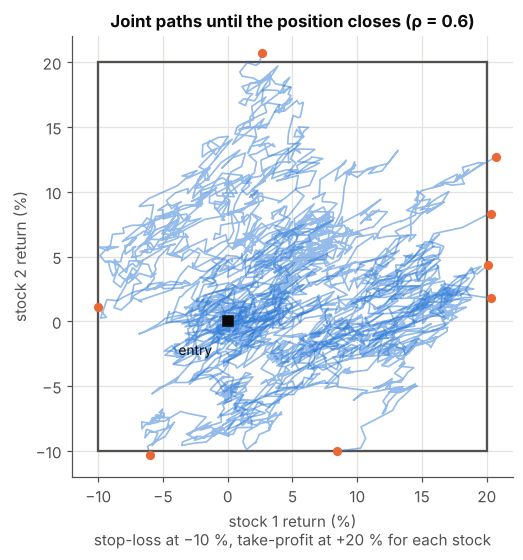

In [2]:
# A few simulated joint paths, drawn in simple-return coordinates until the position is closed
rng = np.random.default_rng(3)
L = np.linalg.cholesky(2 * a)
dt = 1 / 252 / 4                                     # a quarter of a trading day
ret = lambda y: (np.exp(y) - 1) * 100                # log-return -> % return

fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.add_patch(plt.Rectangle((-10, -10), 30, 30, fill=False, ec=plotstyle.MUTED, lw=1.5))
for k in range(8):
    y, path = np.zeros(2), [np.zeros(2)]
    while D.inside(y[None, :], a, dt)[0]:
        y = y + b * dt + np.sqrt(dt) * (L @ rng.standard_normal(2))
        path.append(y.copy())
    path = ret(np.array(path))
    ax.plot(path[:, 0], path[:, 1], color=plotstyle.BLUE, alpha=0.5, lw=1.1)
    ax.plot(*path[-1], "o", color=plotstyle.ORANGE, ms=5)
ax.plot(0, 0, "s", color=plotstyle.INK, ms=6)
ax.text(-1.2, -2.6, "entry", fontsize=9, ha="right")
ax.set(title="Joint paths until the position closes (ρ = 0.6)", xlabel="stock 1 return (%)\nstop-loss at −10 %, take-profit at +20 % for each stock",
       ylabel="stock 2 return (%)", xlim=(-12, 22), ylim=(-12, 22), aspect="equal")
plt.show()

The rectangle is $D$ and the orange dots are the closing points: the position is closed through a face of the rectangle, i.e. when *one* of the two stocks hits *its* barrier. The *expected* quantities we want are averages over all such paths.

## 3. Solving it two ways

**FEM:** solve the two PDEs on an $80\times80$ mesh of the rectangle (whole map of values for every starting point at once).
**Monte Carlo:** simulate $N=40{,}000$ paths per starting point with the boundary-corrected scheme of notebook 2, $\Delta t=10^{-3}$ years.

In [3]:
n = 80
fem_tau = solve_dirichlet_poisson(a, b, one,  zero,          lo, hi, nx=n)     # E[tau]
fem_ret = solve_dirichlet_poisson(a, b, zero, basket_return, lo, hi, nx=n)     # E[basket return]

# starting points: the entry point and a 3x3 grid of "already moved" positions (simple returns)
starts_ret = np.array([-0.05, 0.0, 0.10])
starts = np.log(1 + np.array([(r1, r2) for r1 in starts_ret for r2 in starts_ret]))

t0 = time.perf_counter()
tau_mc, tau_se = feynman_kac_solver(a, b, one,  zero,          starts, D, N=40000, dt=1e-3, seed=1, verbose=False)
ret_mc, ret_se = feynman_kac_solver(a, b, None, basket_return, starts, D, N=40000, dt=1e-3, seed=2, verbose=False)
print(f"Monte Carlo time for both questions at {len(starts)} starting points: {time.perf_counter() - t0:.1f} s\n")

tau_fem, ret_fem = fem_tau(starts), fem_ret(starts)
print("start (r1, r2) |   E[holding time] in trading days   |   E[basket return] at closing, %")
print("               |   Monte Carlo (± se)        FEM     |   Monte Carlo (± se)        FEM")
for s, tm, ts, tf, rm, rs, rf in zip(starts, tau_mc, tau_se, tau_fem, ret_mc, ret_se, ret_fem):
    r1, r2 = np.exp(s) - 1
    print(f"({r1:+.0%}, {r2:+.0%})".ljust(15) + f"|   {252 * tm:6.1f} ± {252 * ts:4.1f}        {252 * tf:6.1f}     |"
          f"   {100 * rm:+6.2f} ± {100 * rs:4.2f}        {100 * rf:+6.2f}")
print(f"\nlargest |MC - FEM| in standard errors:  holding time {np.max(np.abs(tau_mc - tau_fem) / tau_se):.1f},"
      f"  basket return {np.max(np.abs(ret_mc - ret_fem) / ret_se):.1f}")

Monte Carlo time for both questions at 9 starting points: 8.5 s

start (r1, r2) |   E[holding time] in trading days   |   E[basket return] at closing, %
               |   Monte Carlo (± se)        FEM     |   Monte Carlo (± se)        FEM
(-5%, -5%)     |     38.5 ±  0.2          38.2     |    -4.00 ± 0.04         -4.01
(-5%, +0%)     |     44.9 ±  0.2          44.5     |    -1.26 ± 0.04         -1.33
(-5%, +10%)    |     32.8 ±  0.2          32.6     |    +3.35 ± 0.04         +3.37
(+0%, -5%)     |     48.3 ±  0.2          48.3     |    -1.16 ± 0.04         -1.24
(+0%, +0%)     |     64.0 ±  0.3          63.8     |    +1.67 ± 0.05         +1.69
(+0%, +10%)    |     52.7 ±  0.2          52.4     |    +6.43 ± 0.05         +6.41
(+10%, -5%)    |     33.2 ±  0.2          33.2     |    +3.42 ± 0.04         +3.39
(+10%, +0%)    |     50.9 ±  0.2          50.9     |    +6.37 ± 0.04         +6.38
(+10%, +10%)   |     53.8 ±  0.2          53.3     |   +11.41 ± 0.04        +11.47

largest |MC 

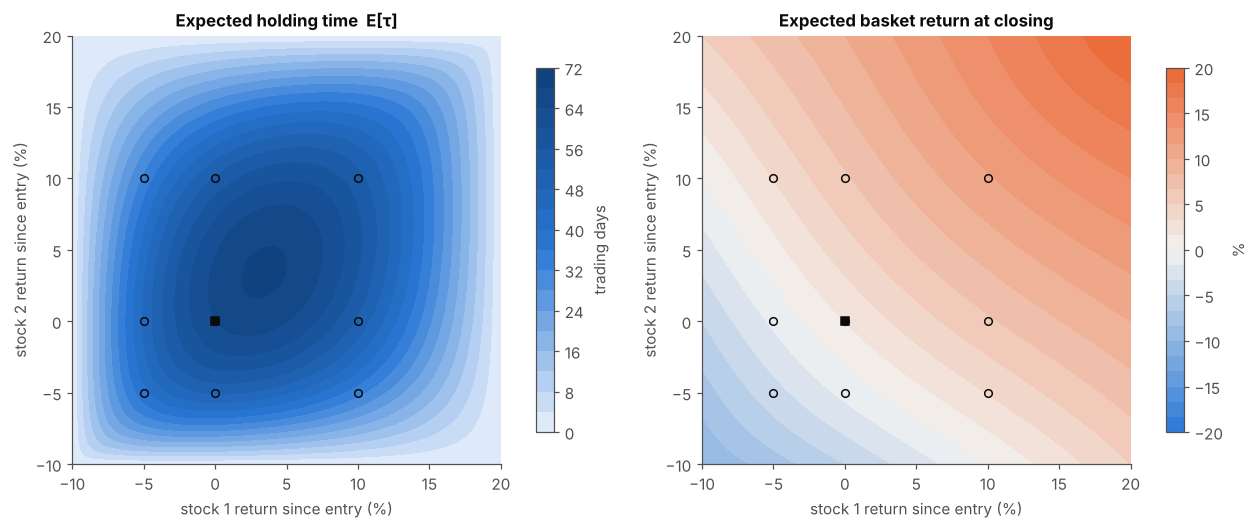

In [4]:
# Full maps from the FEM solution, in simple-return coordinates
nodes = fem_tau.nodes
X, Y = ret(nodes[:, 0]), ret(nodes[:, 1])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.7), constrained_layout=True)

ax = axes[0]
cs = ax.tricontourf(X, Y, 252 * fem_tau.u, levels=20, cmap=plotstyle.SEQUENTIAL)
fig.colorbar(cs, ax=ax, shrink=0.85, label="trading days")
ax.set_title("Expected holding time  E[τ]")

ax = axes[1]
m = 100 * np.abs(fem_ret.u).max()
cs = ax.tricontourf(X, Y, 100 * fem_ret.u, levels=np.linspace(-m, m, 25), cmap=plotstyle.DIVERGING)
fig.colorbar(cs, ax=ax, shrink=0.85, label="%")
ax.set_title("Expected basket return at closing")

for ax in axes:
    ax.plot(0, 0, "s", color=plotstyle.INK, ms=5)
    ax.plot(ret(starts[:, 0]), ret(starts[:, 1]), "o", mfc="none", mec=plotstyle.INK, ms=5)
    ax.set(xlabel="stock 1 return since entry (%)", ylabel="stock 2 return since entry (%)", aspect="equal")
    ax.grid(False)
fig.savefig("figures/application_fields.png")
plt.show()

**Reading the maps** (the square marks the entry point, circles are the Monte Carlo starting points).

* The expected holding time is longest in the middle of the rectangle, far from all four barriers, and tends to $0$ near them: starting close to a barrier, the position closes almost immediately. It is the 2-D version of the parabola $1-x^2$ of notebook 1.
* The expected return of the basket at closing is the harmonic-type function (here with drift) that interpolates the payoffs on the boundary. It is higher when the starting point is already near the take-profit faces and lower near the stop-loss faces.
* Monte Carlo and FEM agree within the statistical errors at every starting point, for two different PDEs (one with a source term, one with boundary data).

## 4. The effect of the correlation

Correlation only modifies the off-diagonal entry of $a$, but the exit problem changes. We compute the expected holding time at the entry point for several values of $\rho$, with Monte Carlo and with FEM.

In [5]:
rhos = [-0.5, 0.0, 0.5, 0.9]
print(f"{'rho':>5} | {'E[holding time], trading days':^40}")
print(f"{'':>5} | {'Monte Carlo (± se)':>20} {'FEM':>10}")
tau_by_rho = []
for r, seed in zip(rhos, range(20, 24)):
    a_r, b_r = model(r)
    mc, se = feynman_kac_solver(a_r, b_r, one, zero, np.zeros(2), D, N=40000, dt=1e-3, seed=seed, verbose=False)
    fe = solve_dirichlet_poisson(a_r, b_r, one, zero, lo, hi, nx=80)(np.zeros((1, 2)))[0]
    tau_by_rho.append((252 * mc, 252 * se, 252 * fe))
    print(f"{r:>+5.1f} | {252 * mc:>13.1f} ± {252 * se:>4.1f} {252 * fe:>10.1f}")

  rho |      E[holding time], trading days      
      |   Monte Carlo (± se)        FEM
 -0.5 |          59.6 ±  0.2       59.8
 +0.0 |          58.9 ±  0.2       58.4
 +0.5 |          62.9 ±  0.2       62.2
 +0.9 |          73.4 ±  0.3       73.2

The closer to $1$ the correlation, the longer the position tends to stay open (about $73$ trading days at $\rho=0.9$ against $59$ at $\rho=0$). A plausible reading: with highly correlated stocks the two barrier events largely coincide, so the position effectively has one chance of being closed instead of two. Between $\rho=-0.5$ and $\rho=0$ the difference is small. A simulation-free formula for this does not exist in 2-D, and that is where a PDE solver (or a Monte Carlo run) earns its keep.

## 5. Why Monte Carlo: the curse of dimensionality

In 2-D FEM is faster and more accurate (notebook 2). What changes if the position holds **$d$ stocks**? The state is $X\in\mathbb{R}^d$ and the PDE lives in $d$ dimensions. A mesh with $m$ points per axis has $m^d$ unknowns, which is hopeless beyond $d\approx3$–$4$. Monte Carlo simulates paths of a $d$-dimensional vector, so the cost per path grows only **polynomially** in $d$.

To measure this honestly we need a high-dimensional problem with a known answer. Take Brownian motion ($a=\tfrac12I$, $b=0$) in the unit ball $B\subset\mathbb{R}^d$ with $g=1$, $\phi=0$:

$$
\tfrac12\Delta u=-1\ \text{in }B,\quad u=0\ \text{on }\partial B
\quad\Longrightarrow\quad u(x)=\frac{1-|x|^2}{d}=\mathbb{E}^x[\tau_B],
$$

for any $d$ (check: $\tfrac12\Delta\big(-|x|^2/d\big)=-1$). We start at $x=(0.6,0,\dots,0)$, where $u=0.64/d$. The time step is scaled as $\Delta t=0.02/d^2$ so the step stays small relative to the distance to the boundary as $d$ grows.

In [6]:
dims = [2, 3, 5, 10, 20]
N = 10000
rows = []
for d in dims:
    x0 = np.zeros(d); x0[0] = 0.6
    exact = 0.64 / d
    dt_d = 0.02 / d**2
    row = {"d": d, "exact": exact}
    for corr in (False, True):
        t0 = time.perf_counter()
        u, se = feynman_kac_solver(0.5 * np.eye(d), np.zeros(d), one, zero, x0, Ball(np.zeros(d), 1.0),
                                   N=N, dt=dt_d, boundary_correction=corr, seed=d, verbose=False)
        row[corr] = (u, se, time.perf_counter() - t0)
    rows.append(row)

print(f"{'d':>3} | {'FEM unknowns (61^d)':>20} | {'exact':>8} | {'naive: rel. error':>18} | {'corrected: rel. error':>22} | {'MC time (corr.)':>15}")
for r in rows:
    nf, (u1, s1, _), (u2, s2, t2) = 61.0 ** r["d"], r[False], r[True]
    print(f"{r['d']:>3} | {nf:>20.1e} | {r['exact']:>8.4f} | {abs(u1 - r['exact']) / r['exact']:>17.1%} | "
          f"{abs(u2 - r['exact']) / r['exact']:>21.1%} | {t2:>13.1f} s")

  d |  FEM unknowns (61^d) |    exact |  naive: rel. error |  corrected: rel. error | MC time (corr.)
  2 |              3.7e+03 |   0.3200 |             13.7% |                  0.6% |           0.1 s
  3 |              2.3e+05 |   0.2133 |              8.4% |                  0.1% |           0.1 s
  5 |              8.4e+08 |   0.1280 |              5.3% |                  0.8% |           0.3 s
 10 |              7.1e+17 |   0.0640 |              2.5% |                  0.7% |           1.2 s
 20 |              5.1e+35 |   0.0320 |              1.5% |                  0.2% |           5.8 s

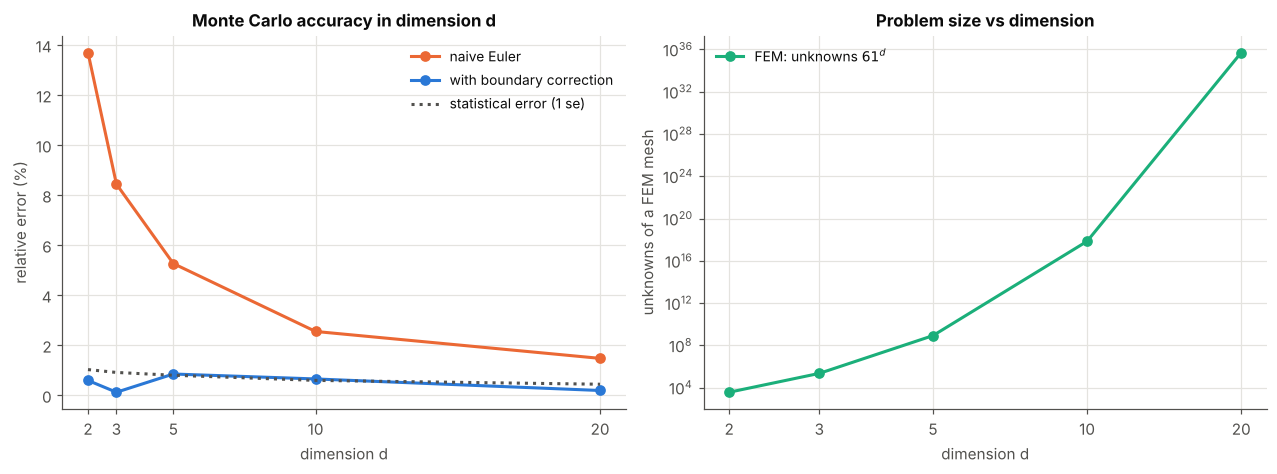

In [7]:
d_arr = np.array([r["d"] for r in rows])
rel = lambda key: np.array([abs(r[key][0] - r["exact"]) / r["exact"] for r in rows]) * 100
rel_se = np.array([r[True][1] / r["exact"] for r in rows]) * 100
times = np.array([r[True][2] for r in rows])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)
ax = axes[0]
ax.plot(d_arr, rel(False), "o-", color=plotstyle.ORANGE, label="naive Euler")
ax.plot(d_arr, rel(True), "o-", color=plotstyle.BLUE, label="with boundary correction")
ax.plot(d_arr, rel_se, ls=":", color=plotstyle.MUTED, label="statistical error (1 se)")
ax.set(title="Monte Carlo accuracy in dimension d", xlabel="dimension d", ylabel="relative error (%)", xticks=d_arr)
ax.legend(loc="upper right")

ax = axes[1]
ax.loglog(d_arr, 61.0 ** d_arr, "o-", color=plotstyle.AQUA, label=r"FEM: unknowns $61^d$")
ax.set(title="Problem size vs dimension", xlabel="dimension d", ylabel="unknowns of a FEM mesh", xticks=d_arr)
ax.set_xticklabels([str(v) for v in d_arr]); ax.minorticks_off()
ax.legend(loc="upper left")
fig.savefig("figures/dimension.png")
plt.show()

* In $d=20$ a finite-element mesh with only $61$ points per axis would have $\sim10^{35}$ unknowns, impossible to store. Monte Carlo solves the same problem in seconds, with a relative error of a fraction of a percent. Its cost per path grows roughly like $d^2$ here ($d$ coordinates and $\propto d$ steps), not exponentially.
* The boundary correction is again the better choice at equal cost, most visibly in low dimension where the naive bias is largest.
* The same $\sqrt{\Delta t}$ trap exists in every dimension, which is why the validation of notebook 2 matters: a "converged-looking" high-dimensional run can be biased.

---

## Takeaways

1. A question about **when a random process first leaves a region** becomes, through the Dynkin formula, a **boundary value problem** whose solution is the answer for *every* starting point at once.
2. Conversely, a PDE solver and a path simulator are **two independent ways to compute the same number**, so each validates the other (all the agreement above is between independently computed quantities).
3. Finite elements win in low dimension and regular geometry. **Monte Carlo wins when the dimension grows**, because it never builds a mesh.

⬅️ Back to [the project README](README.md)